# Demo — AI moderna per il suono: rappresentazioni e generazione

Le demo seguono il capitolo 5 e le slide: embedding condivisi audio-testo (CLAP), quantizzazione su dizionario (codebook), ricostruzione e morphing nello spazio latente continuo (RAVE), corruzione progressiva con rumore (diffusione) e generazione condizionata da testo (AudioLDM).
Le funzioni `audiolab` sono documentate nell'[Appendice B](https://giulianogrossi.github.io/infomm-audio-AI/app-b-manuale-audiolab.html).

## 0. Configurazione

In [1]:
# Configurazione: percorsi, libreria audiolab e impostazioni comuni
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "lab-2026/audiolab").is_dir())
sys.path.insert(0, str(ROOT / "lab-2026"))
import audiolab as al

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
np.set_printoptions(precision=3, suppress=True)

## Demo 1 — Una matrice audio-testo da CLAP reale

Usiamo gli embedding precalcolati con il checkpoint `laion/clap-htsat-unfused` (`al.CLAP_MODEL_ID`) su tre suoni reali del corso (parlato, nota di chitarra, abbaio) e quattro descrizioni candidate (`al.PHRASES`).

Modello: laion/clap-htsat-unfused revisione: 8fa0f1c6d0


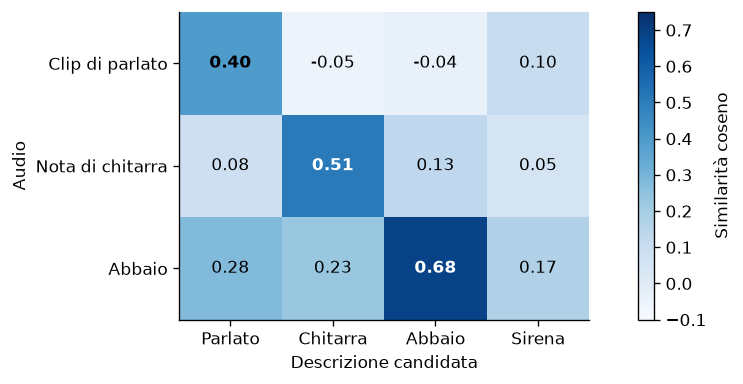

speech1.wav → The sound of a person speaking.
Guitar_C4.wav → The sound of a guitar playing a note.
100032-3-0-0.mp3 → The sound of a dog barking.


In [2]:
base = ROOT / "lab-2026/materiali/05-clap"
meta_clap = json.loads((base / "provenienza.json").read_text())
with np.load(base / "embedding.npz") as archivio:
    audio_emb = archivio["audio"]
    testo_emb = archivio["testo"]
audio_emb = audio_emb / np.linalg.norm(audio_emb, axis=1, keepdims=True)
testo_emb = testo_emb / np.linalg.norm(testo_emb, axis=1, keepdims=True)
sim = audio_emb @ testo_emb.T
print("Modello:", meta_clap["model_id"], "revisione:", meta_clap["revision"][:10])
fig, ax = plt.subplots(figsize=(8.5, 3.3))
im = ax.imshow(sim, cmap="Blues", vmin=-0.1, vmax=0.75)
ax.set_xticks(range(4), ["Parlato", "Chitarra", "Abbaio", "Sirena"])
ax.set_yticks(range(3), ["Clip di parlato", "Nota di chitarra", "Abbaio"])
for i in range(3):
    for j in range(4):
        ax.text(j, i, f"{sim[i,j]:.2f}", ha="center", va="center",
                color="white" if sim[i,j] > 0.42 else "black", fontweight="bold" if i == j else "normal")
ax.set(xlabel="Descrizione candidata", ylabel="Audio")
fig.colorbar(im, ax=ax, label="Similarità coseno")
plt.tight_layout(); plt.show()
for i, percorso in enumerate(meta_clap["files"]):
    print(Path(percorso).name, "→", meta_clap["frasi"][sim[i].argmax()])

## Demo 2 — Assegnazione al prototipo più vicino (codebook)

Un quantizzatore vettoriale (VQ) sostituisce ogni vettore continuo con l'indice intero del prototipo più vicino nel dizionario (*codebook*), trasformando una traiettoria continua in una sequenza di token discreti.

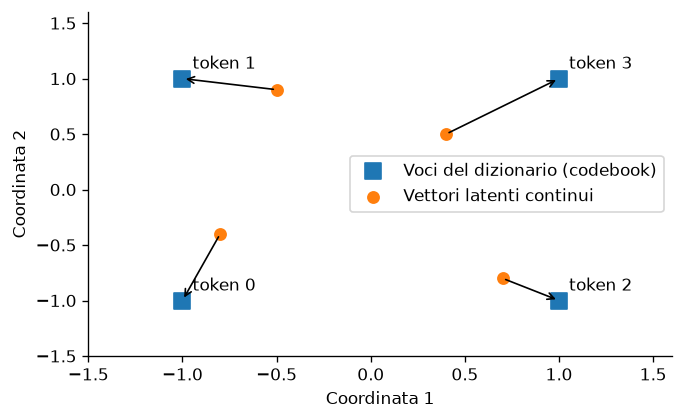

Sequenza di token discreti trasmessa al decoder: [0 1 2 3]


In [3]:
codebook = np.array([[-1., -1.], [-1., 1.], [1., -1.], [1., 1.]])
vettori = np.array([[-.8, -.4], [-.5, .9], [.7, -.8], [.4, .5]])
indici = ((vettori[:, None, :] - codebook[None, :, :])**2).sum(2).argmin(1)
fig, ax = plt.subplots(figsize=(5.8, 3.6))
ax.scatter(*codebook.T, marker="s", s=100, label="Voci del dizionario (codebook)")
ax.scatter(*vettori.T, s=45, label="Vettori latenti continui")
for k, punto in enumerate(codebook):
    ax.annotate(f"token {k}", punto, xytext=(6, 6), textcoords="offset points")
for punto, k in zip(vettori, indici):
    ax.annotate("", xy=codebook[k], xytext=punto, arrowprops={"arrowstyle": "->"})
ax.set(xlim=(-1.5, 1.6), ylim=(-1.5, 1.6), xlabel="Coordinata 1", ylabel="Coordinata 2")
ax.legend(); plt.tight_layout(); plt.show()
print("Sequenza di token discreti trasmessa al decoder:", indici)

## Demo 3 — Un VAE audio al lavoro: ricostruzione e morphing con RAVE

La demo usa i materiali reali prodotti con **RAVE** (`voice-multi`, addestrato su voci parlate e cantate a 48 kHz), che comprime ogni blocco di 2048 campioni (circa 42,7 ms) in **11 coordinate latenti**.

**Funzioni usate.** [`al.compare_audio()`](https://giulianogrossi.github.io/infomm-audio-AI/app-b-manuale-audiolab.html), [`al.envelope_corr()`](https://giulianogrossi.github.io/infomm-audio-AI/app-b-manuale-audiolab.html), [`al.snr_db()`](https://giulianogrossi.github.io/infomm-audio-AI/app-b-manuale-audiolab.html).

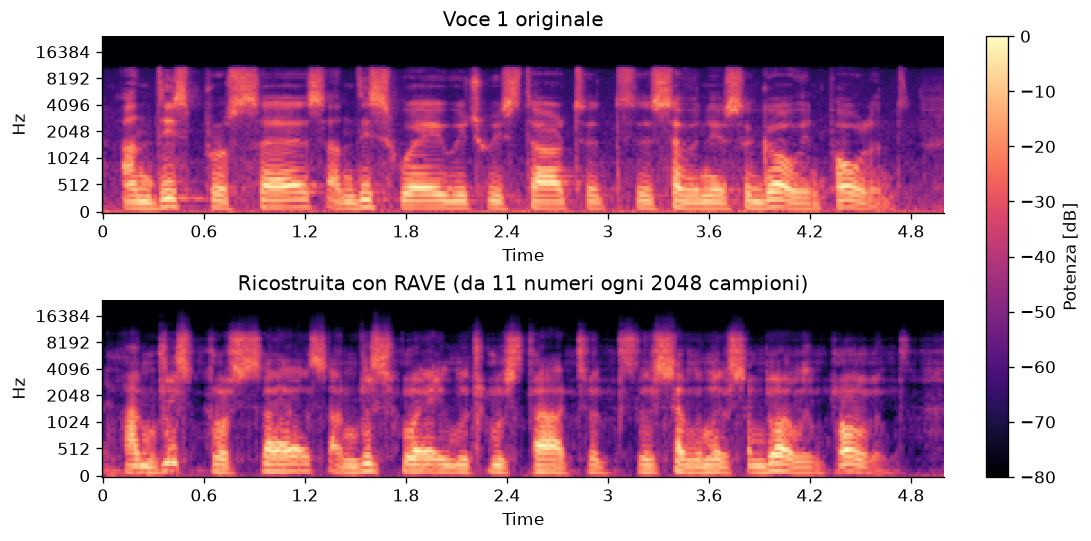

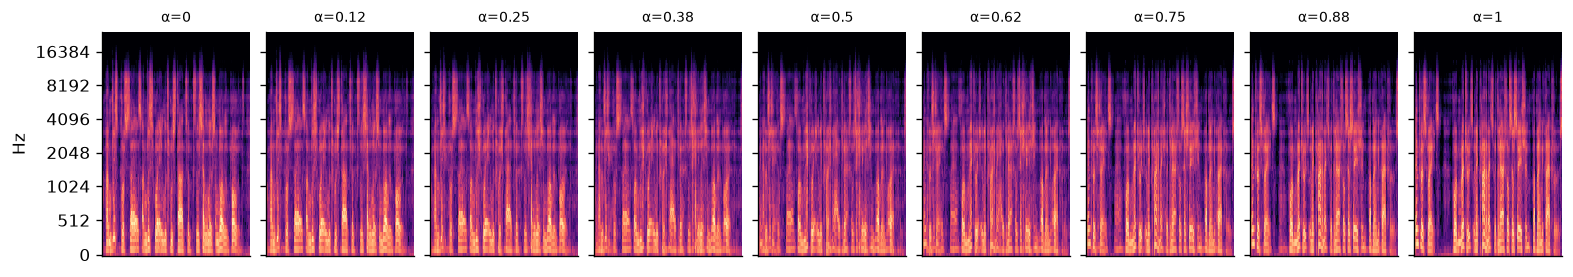

Latenti: 11 numeri ogni blocco da 2048 campioni | modello: voice-multi-b2048-r48000-z11.ts
Guadagno comune per l'ascolto: 0.0 dB


**Voce 1 originale** — 5.00 s; picco 0.422; RMS 0.0835

**Voce 1 ricostruita** — 5.00 s; picco 0.599; RMS 0.0791

In [4]:
base = ROOT / "lab-2026/materiali/05-vae"
meta = json.loads((base / "provenienza.json").read_text())
voce1, sr = sf.read(base / "voce1.wav", dtype="float32")
ric1, _ = sf.read(base / "voce1_ricostruita.wav", dtype="float32")

coppia = [librosa.feature.melspectrogram(y=y, sr=sr, n_fft=2048, hop_length=512, n_mels=80) for y in (voce1, ric1)]
rif = max(float(M.max()) for M in coppia)
fig, axes = plt.subplots(2, 1, figsize=(9, 4.4), constrained_layout=True)
for ax, M, tit in zip(axes, coppia, ["Voce 1 originale", "Ricostruita con RAVE (da 11 numeri ogni 2048 campioni)"]):
    im = librosa.display.specshow(librosa.power_to_db(M, ref=rif, top_db=None),
                                  sr=sr, hop_length=512, x_axis="time", y_axis="mel",
                                  ax=ax, vmin=-80, vmax=0, cmap="magma")
    ax.set_title(tit)
fig.colorbar(im, ax=axes, label="Potenza [dB]")
plt.show()

morphs = [sf.read(base / f"morph_{i}.wav", dtype="float32")[0] for i in range(9)]
M = [librosa.feature.melspectrogram(y=y, sr=sr, n_fft=2048, hop_length=512, n_mels=80) for y in morphs]
rif = max(float(x.max()) for x in M)
fig, axes = plt.subplots(1, 9, figsize=(13, 2.2), sharey=True, constrained_layout=True)
for idx, (ax, x, a) in enumerate(zip(axes, M, meta["alpha"])):
    librosa.display.specshow(librosa.power_to_db(x, ref=rif, top_db=None),
                             sr=sr, hop_length=512, y_axis="mel", ax=ax,
                             vmin=-80, vmax=0, cmap="magma")
    if idx > 0:
        ax.set_ylabel("")
    ax.set_title(f"α={a:.2g}", fontsize=8.5)
plt.show()

z1 = np.load(base / "latenti.npz")["voce1"]
print(f"Latenti: {z1.shape[0]} numeri ogni blocco da 2048 campioni | modello: {meta['file']}")
al.compare_audio([("Voce 1 originale", voce1), ("Voce 1 ricostruita", ric1)], sr)

## Demo 4 — Effetto progressivo del rumore su un segnale (processo Forward)

Dato un segnale pulito $x_0$ a varianza unitaria e un rumore gaussiano standard $\varepsilon \sim \mathcal{N}(0, 1)$, uno stadio rumoroso con quota di rumore $q \in [0, 1]$ si ottiene come $x_q = \sqrt{1 - q}\,x_0 + \sqrt{q}\,\varepsilon$.

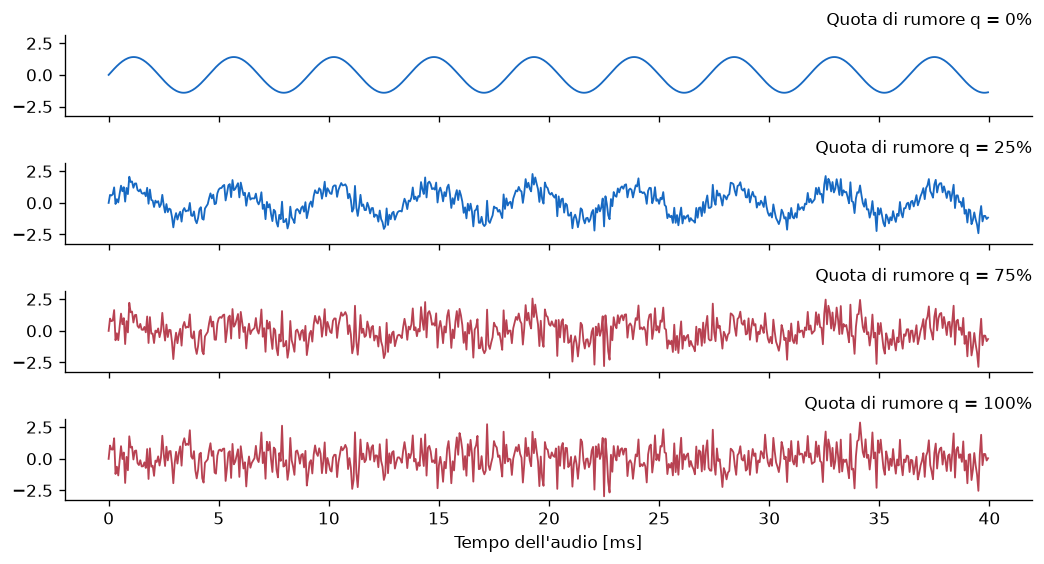

In [5]:
rng = np.random.default_rng(12)
t = np.arange(640) / 16000
pulito = np.sin(2 * np.pi * 220 * t)
pulito /= pulito.std()
rumore = rng.standard_normal(len(t))
fig, axes = plt.subplots(4, 1, figsize=(8.8, 4.8), sharex=True, sharey=True)
for ax, quota in zip(axes, [0., .25, .75, 1.]):
    segnale = np.sqrt(1 - quota) * pulito + np.sqrt(quota) * rumore
    ax.plot(t * 1000, segnale, lw=1.1, color="#1769C2" if quota < 0.5 else "#B84252")
    ax.set_title(f"Quota di rumore q = {quota:.0%}", fontsize=10, loc="right")
axes[-1].set_xlabel("Tempo dell'audio [ms]")
plt.tight_layout(); plt.show()

## Demo 5 — Generazione da testo: tre prove a confronto (AudioLDM)

Mettiamo a confronto i tre clip generati variando **una sola variabile alla volta** (`A` e `B` hanno lo stesso prompt ma seed `42` e `43`; `A` e `C` hanno lo stesso seed `42` ma stanza asciutta vs riverberante). Per lanciare la generazione dal vivo su una macchina predisposta basta impostare `ESEGUI_GENERAZIONE = True`.

**Funzioni usate.** [`al.load_samples()`](https://giulianogrossi.github.io/infomm-audio-AI/app-b-manuale-audiolab.html), [`al.generate()`](https://giulianogrossi.github.io/infomm-audio-AI/app-b-manuale-audiolab.html), [`al.safe_audio()`](https://giulianogrossi.github.io/infomm-audio-AI/app-b-manuale-audiolab.html), [`al.to_dbfs()`](https://giulianogrossi.github.io/infomm-audio-AI/app-b-manuale-audiolab.html).

Clip A: durata 5.0 s | inferenza 17.3 s (mps) | picco -1.2 dBFS


Clip B: durata 5.0 s | inferenza 3.0 s (mps) | picco -73.5 dBFS


Clip C: durata 5.0 s | inferenza 3.3 s (mps) | picco -6.6 dBFS


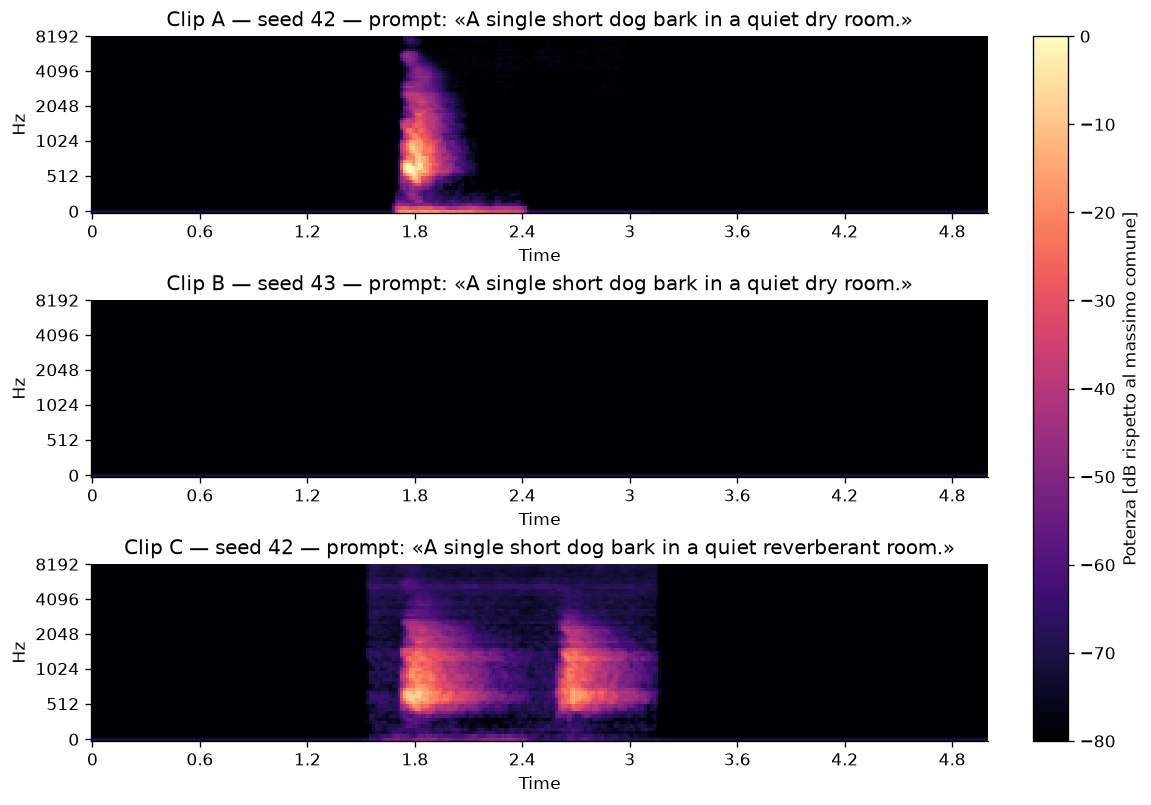

In [6]:
from datetime import datetime, timezone
ESEGUI_GENERAZIONE = False
DEVICE = "cpu"  # "cuda" o "mps" soltanto su un ambiente predisposto e collaudato
cartella = al.generation.OFFLINE_DIR
if ESEGUI_GENERAZIONE:
    nome = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    cartella = al.generate(ROOT / "output/generazione-audio" / nome, device=DEVICE, steps=25)

clips = al.load_samples(cartella)
picco = max(float(np.max(np.abs(y))) for _, y, _, _ in clips)
guadagno = min(1.0, 0.8 / max(picco, 1e-12))
potenze = [librosa.feature.melspectrogram(y=y, sr=sr, n_fft=1024,
            hop_length=256, n_mels=64) for _, y, sr, _ in clips]
ref = max(float(s.max()) for s in potenze)
fig, axes = plt.subplots(3, 1, figsize=(9.5, 6.6), constrained_layout=True)
for ax, (nome, y, sr, meta), S in zip(axes, clips, potenze):
    db = librosa.power_to_db(S, ref=max(ref, 1e-12), top_db=None)
    im = librosa.display.specshow(db, sr=sr, hop_length=256, x_axis="time", y_axis="mel",
                                  ax=ax, vmin=-80, vmax=0, cmap="magma")
    ax.set_title(f"Clip {nome} — seed {meta['seed']} — prompt: «{meta['prompt']}»")
    print(f"Clip {nome}: durata {len(y)/sr:.1f} s | inferenza {meta['inference_seconds']:.1f} s "
          f"({meta['device']}) | picco {al.to_dbfs(np.max(np.abs(y))):.1f} dBFS")
    display(al.safe_audio(y * guadagno, sr=sr, normalize=False))
fig.colorbar(im, ax=axes, label="Potenza [dB rispetto al massimo comune]")
plt.show()